In [1]:
import scanpy as sc
import scvi

import seaborn as sns
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print(scvi.__version__)              # 1.5.0.post1
# Load dataset
adata_phase = sc.read_h5ad("data/adata_phase.h5ad")

1.5.0.post1


In [2]:
# Create new anndata for integration
adata_integrated = adata_phase.copy()

# Set parameters for the scVI model
scvi.model.SCVI.setup_anndata(adata_integrated, 
                              layer = "counts", 
                              batch_key = "sample", 
                              categorical_covariate_keys =[ "phase", "mitoFr"])

model = scvi.model.SCVI(adata_integrated, 
                        n_layers = 2, 
                        n_latent = 30, 
                        gene_likelihood = "nb")
model

SCVI model with the following parameters: 
n_hidden: 128, n_latent: 30, n_layers: 2, dropout_rate: 0.1, dispersion: gene, gene_likelihood: nb, 
latent_distribution: normal.
Training status: Not Trained
Model's adata is minified?: False

In [3]:
# Train encoder and decoder neural networks
# This step will take several minutes
model.train(max_epochs = 100)

GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
You are using a CUDA device ('NVIDIA GeForce RTX 3060') that has Tensor Cores. To properly utilize them, you should set `torch.set_float32_matmul_precision('medium' | 'high')` which will trade-off precision for performance. For more details, read https://pytorch.org/docs/stable/generated/torch.set_float32_matmul_precision.html#torch.set_float32_matmul_precision
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
C:\Users\user\anaconda3\envs\pyscRNA\Lib\site-packages\lightning\pytorch\trainer\connectors\data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=7` in the `Data

Training:   0%|          | 0/100 [00:00<?, ?it/s]

`Trainer.fit` stopped: `max_epochs=100` reached.


In [4]:
adata_integrated.obsm["X_scvi"] = model.get_latent_representation()

In [5]:
adata_integrated

AnnData object with n_obs × n_vars = 29629 × 14167
    obs: 'n_genes', 'sample', 'n_genes_by_counts', 'total_counts', 'cells', 'log10GenesPerUMI', 'log1p_n_genes_by_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mito', 'log1p_total_counts_mito', 'pct_counts_mito', 'mito_ratio', 'S_score', 'G2M_score', 'phase', 'mitoFr', '_scvi_batch', '_scvi_labels'
    var: 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'mito', 'log1p_mean_counts', 'log1p_total_counts', 'n_counts', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm', 'highly_variable_nbatches'
    uns: 'hvg', 'log1p', 'mitoFr_colors', 'pca', 'phase_colors', '_scvi_uuid', '_scvi_manager_uuid'
    obsm: 'X_pca', '_scvi_extra_categorical_covs', 'X_scvi'
    varm: 'PCs'
    layers: 'counts', 'log', 'median', None (.X)

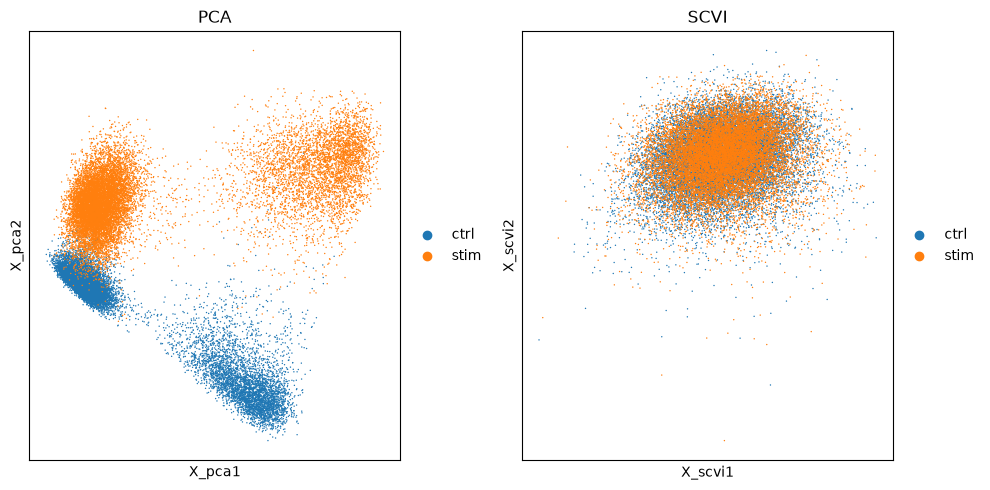

In [6]:
# Create plot with the correct dimensions
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

# Plot unintegrated PCA
sc.pl.embedding(adata_integrated, basis='X_pca', 
                color='sample', ax=axes[0], 
                title="PCA", show=False)
# Plot integrated scVI latent space
sc.pl.embedding(adata_integrated, basis='X_scvi', 
                color='sample', ax=axes[1], 
                title="SCVI", show=False)

plt.tight_layout()
plt.show()

In [7]:
adata_integrated.write_h5ad("data/adata_integrated.h5ad")